In [ ]:
Name - Tanish Arora
addmission no - 2026B15310502
course - Btech CSE (AI/ML)
Section - AI/ML 6
HCL Batch no - 7

In [5]:
%pip -q install kagglehub

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path(kagglehub.dataset_download(
    "abdurrahmanhakanacar/lego-sets-themes-and-minifigures-1975-2025"
))

sets = pd.read_csv(next(folder.rglob("lego_sets_1975_2025.csv")), dtype="string")
themes = pd.read_csv(next(folder.rglob("lego_themes_1975_2025.csv")), dtype="string")

print("Total sets:", len(sets))
print("Total themes:", len(themes))
display(sets.head(3))

Using Colab cache for faster access to the 'lego-sets-themes-and-minifigures-1975-2025' dataset.
Total sets: 18540
Total themes: 464


,set_num,name,year,theme_name,parent_theme,num_parts,num_minifigs,num_unique_colors,has_minifigs,img_url
0,75419-1,Death Star,2025,Ultimate Collector Series,Star Wars,9031,40,34,True,https://cdn.rebrickable.com/media/sets/75419-1...
1,10366-1,Tropical Aquarium,2025,Icons,Icons,4154,0,45,False,https://cdn.rebrickable.com/media/sets/10366-1...
2,21356-1,River Steamboat,2025,LEGO Ideas and CUUSOO,LEGO Ideas and CUUSOO,4090,0,28,False,https://cdn.rebrickable.com/media/sets/21356-1...


In [ ]:
columns = ["set_num", "name", "year", "theme_name", "parent_theme", "num_parts"]
sets = sets[columns].copy()

for table in [sets, themes]:
    table["theme_name"] = table["theme_name"].str.strip()
    table["parent_theme"] = table["parent_theme"].str.strip().fillna("")

sets["year"] = pd.to_numeric(sets["year"], errors="coerce")
sets["num_parts"] = pd.to_numeric(sets["num_parts"], errors="coerce")

print("Missing or unreadable years:", sets["year"].isna().sum())
print("Duplicate theme IDs:", themes["id"].dropna().duplicated().sum())

old_sets = sets[sets["year"].between(2015, 2019)].copy()
new_sets = sets[sets["year"].between(2020, 2024)].copy()
print("2015–2019:", len(old_sets), "sets")
print("2020–2024:", len(new_sets), "sets")

Missing or unreadable years: 0
Duplicate theme IDs: 0
2015–2019: 3534 sets
2020–2024: 3874 sets


In [ ]:
test = new_sets.copy().reset_index(drop=True)

test.loc[0, "num_parts"] = -10
test.loc[1, "theme_name"] = "Demo Unknown Theme"
test.loc[2, "num_parts"] = np.nan
test = pd.concat([test, test.iloc[[3]]], ignore_index=True)
test["extra_note"] = "demo"

expected_date = pd.Timestamp("2025-01-01")
arrival_date = pd.Timestamp("2025-01-04")
delay = (arrival_date - expected_date).days

display(test.head(4))

,set_num,name,year,theme_name,parent_theme,num_parts,extra_note
0,2000409-2,Window Exploration Bag,2024,Serious Play,Educational and Dacta,-10,demo
1,10333-1,The Lord of the Rings: Barad-dûr,2024,Demo Unknown Theme,Icons,5478,demo
2,21061-1,Notre-Dame de Paris,2024,Architecture,Architecture,<NA>,demo
3,76271-1,Batman: The Animated Series Gotham City,2024,Batman,Super Heroes DC,4210,demo


In [ ]:
theme_cols = ["theme_name", "parent_theme"]
known_themes = themes[theme_cols].dropna().drop_duplicates()

def check(table):
    rows = table.reindex(columns=columns)
    pieces = rows["num_parts"].dropna()

    pairs = rows[theme_cols].dropna()
    matched = pairs.merge(known_themes, how="left", on=theme_cols,
                          indicator=True, validate="many_to_one")

    return {
        "Missing columns": len(set(columns) - set(table.columns)),
        "Extra columns": len(set(table.columns) - set(columns)),
        "Empty required cells": rows.drop(columns="parent_theme").isna().sum().sum(),
        "Duplicate set IDs": rows["set_num"].dropna().duplicated().sum(),
        "Invalid piece counts": ((pieces < 0) | (pieces % 1 != 0)).sum(),
        "Unknown theme pairs": (matched["_merge"] == "left_only").sum()
    }

summary = pd.DataFrame({
    "Old": check(old_sets),
    "New": check(new_sets),
    "Test": check(test)
})
display(summary)

,Old,New,Test
Missing columns,0,0,0
Extra columns,0,0,1
Empty required cells,0,0,1
Duplicate set IDs,0,0,1
Invalid piece counts,0,0,1
Unknown theme pairs,0,0,1


Excluded: 0 | Median pieces: 70.0
Excluded: 0 | Median pieces: 107.0


,2015–2019,2020–2024
0–99,57.8,49.1
100–499,28.9,30.5
500–999,8.4,11.2
1000+,4.8,9.2


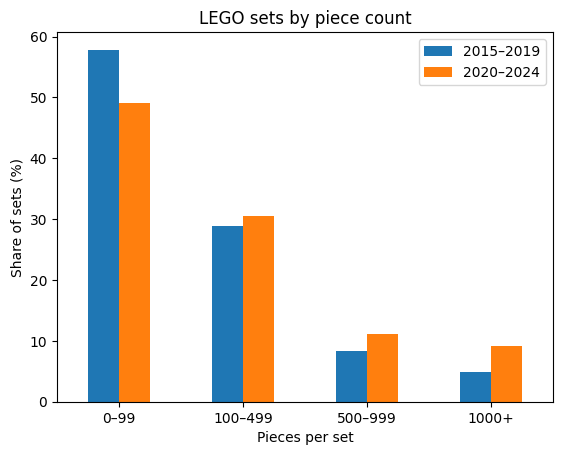

In [ ]:
groups = ["0–99", "100–499", "500–999", "1000+"]
bins = [0, 100, 500, 1000, np.inf]

def size_share(table):
    pieces = table["num_parts"].dropna()
    pieces = pieces[(pieces >= 0) & (pieces % 1 == 0)]
    print("Excluded:", len(table) - len(pieces), "| Median pieces:", np.median(pieces))

    counts, edges = np.histogram(pieces, bins=bins)
    return counts * 100 / len(pieces)

report = pd.DataFrame(index=groups)
report["2015–2019"] = size_share(old_sets)
report["2020–2024"] = size_share(new_sets)
display(report.round(1))

report.plot.bar(rot=0, title="LEGO sets by piece count",
                xlabel="Pieces per set", ylabel="Share of sets (%)")
plt.show()

In [3]:
drift_limit = 10       # percentage points
volume_limit = 30      # percent
late_limit = 2         # days

change = report["2020–2024"] - report["2015–2019"]
drift = change.abs().max()
volume = 100 * (len(new_sets) - len(old_sets)) / len(old_sets)

print("Biggest shift:", change.abs().idxmax(), "pieces")
print("Size share change:", round(drift, 1), "percentage points")
print("Set count change:", round(volume, 1), "%")

alerts = []
for sample in ["New", "Test"]:
    for issue, count in summary[sample].items():
        if count > 0:
            alerts.append([sample, issue, count, 0, "Error"])

if drift > drift_limit:
    alerts.append(["New", "Size drift (points)", drift, drift_limit, "Warning"])
if abs(volume) > volume_limit:
    alerts.append(["New", "Set count change (%)", volume, volume_limit, "Warning"])
if delay > late_limit:
    alerts.append(["Test", "Late delivery (days)", delay, late_limit, "Warning"])

log = pd.DataFrame(alerts, columns=["Sample", "Issue", "Observed", "Limit", "Level"])
display(log.round(1))

NameError: name 'report' is not defined

In [4]:
summary.to_csv("quality_summary.csv")
report.round(2).to_csv("drift_report.csv", index_label="Piece group")
log.to_csv("alert_log.csv", index=False)

group = change.abs().idxmax()
print("Largest change was in the", group, "piece group.")
print("Earlier share:", round(report.loc[group, "2015–2019"], 1), "%")
print("Later share:", round(report.loc[group, "2020–2024"], 1), "%")
print("The test file arrived", delay, "days late.")
print("Saved all 3 reports.")

NameError: name 'summary' is not defined